# Lab: Logistic Regression for Text Classification (Binary and Multiclass)

### Introduction

In this lab you will build complete text-classification pipelines with **logistic regression**, from raw text to a critical analysis of the results. You will work on two realistic business problems:

1. **Binary classification - Movie review sentiment.** Decide whether a movie review is *positive* (1) or *negative* (0). Typical use: monitoring opinions about products or services automatically.
2. **Multiclass classification - Newsgroup topic classification.** Decide in which discussion group a post was published: *baseball*, *medicine*, *space* or *gun politics*. Typical use: automatically routing or tagging documents by topic.

Both datasets are **real, publicly available corpora that the notebook downloads automatically** (see the setup cell below), so there is nothing to upload or install by hand. An internet connection is needed the first time you run the setup cell.

By the end of this lab, you will be able to:
1. Explore and preprocess text data (lowercasing, cleaning, tokenization, stop-words, stemming, lemmatization).
2. Extract features with **TF-IDF**, understand its mathematical basis and the role of its parameters.
3. Train logistic regression models for binary (sigmoid) and multiclass (softmax) problems with `sklearn`.
4. Evaluate models properly: train/test split, precision / recall / F1, confusion matrices, and cross-validation without data leakage.
5. Interpret the model (which words drive each prediction), tune regularization and n-grams, and analyze errors.

---

### Lab roadmap

| Exercise | Topic |
|---|---|
| 1 | Dataset exploration and text preprocessing |
| 2 | Feature extraction with TF-IDF |
| 3 | Logistic regression: binary and multiclass |
| 4 | Model evaluation and cross-validation |
| 5 | Model interpretation, hyperparameters and error analysis |

An appendix at the end of the notebook walks through a small, hand-computed TF-IDF example.

---

### Datasets

1. **Binary dataset - IMDb Movie Reviews** (Maas et al., 2011, Stanford)
   - **Description:** we use a random, balanced sample of 10,000 of the 50,000 labeled movie reviews. Reviews are long (about 230 words on average), contain HTML remnants (`<br />`), negations ("not good"), sarcasm and mixed opinions.
   - **Classes:** Positive (1), Negative (0)

2. **Multiclass dataset - 20 Newsgroups** (Lang, 1995, loaded with `sklearn.datasets.fetch_20newsgroups`)
   - **Description:** roughly 3,800 Usenet posts from 4 of the 20 newsgroups. Headers, signatures and quoted replies are removed, so the model must rely on the content of the post. Two of the topics (`sci.med`, `sci.space`) are related, which makes the problem less trivial.
   - **Classes:** `rec.sport.baseball`, `sci.med`, `sci.space`, `talk.politics.guns`

### Setup: imports and dataset generation

Run the next cell as it is. You do **not** need to modify it. It imports the main libraries, downloads the two corpora (the first run takes a minute or two) and creates two DataFrames, `reviews_df` and `news_df`, each with a `text` column and a `label` column.

In [2]:
import os
import re
import string

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
from sklearn.model_selection import train_test_split

SEED = 42
pd.set_option("display.max_colwidth", 150)

# ---------------------------------------------------------------------------
# Corpus loaders (using Hugging Face datasets with proper namespaced IDs)
# ---------------------------------------------------------------------------
def load_imdb_reviews(n_samples=10000, seed=SEED):
    """
    Binary dataset: IMDb Large Movie Review Dataset via Hugging Face.
    label 1 = positive review, 0 = negative review.
    """
    print("Loading IMDb reviews from Hugging Face...")
    # Use the namespaced repository ID to satisfy huggingface_hub requirements
    dataset = load_dataset("stanfordnlp/imdb")

    # Combine train and test splits to sample from the full pool
    df = pd.concat([
        pd.DataFrame(dataset["train"]),
        pd.DataFrame(dataset["test"])
    ], ignore_index=True)

    pos = df[df["label"] == 1].sample(n_samples // 2, random_state=seed)
    neg = df[df["label"] == 0].sample(n_samples // 2, random_state=seed)
    return pd.concat([pos, neg]).sample(frac=1, random_state=seed).reset_index(drop=True)


NEWS_CATEGORIES = ["rec.sport.baseball", "sci.med", "sci.space", "talk.politics.guns"]

def load_newsgroups(categories=NEWS_CATEGORIES, seed=SEED):
    """
    Multiclass dataset: 20 Newsgroups via Hugging Face, restricted to 4 topics.
    """
    print("Loading 20 Newsgroups from Hugging Face...")
    dataset = load_dataset("SetFit/20_newsgroups")

    # Combine available splits
    splits = []
    if "train" in dataset:
        splits.append(pd.DataFrame(dataset["train"]))
    if "test" in dataset:
        splits.append(pd.DataFrame(dataset["test"]))
    df = pd.concat(splits, ignore_index=True)

    # Map integer labels to string category names if necessary
    if "label_text" in df.columns:
        df["label"] = df["label_text"]
    elif pd.api.types.is_integer_dtype(df["label"]):
        label_names = dataset["train"].features["label"].names
        df["label"] = df["label"].map(lambda x: label_names[x])

    # Filter by the requested categories and drop empty/near-empty posts
    df = df[df["label"].isin(categories)]
    df = df[df["text"].str.split().str.len() >= 10]

    return df.sample(frac=1, random_state=seed).reset_index(drop=True)


reviews_df = load_imdb_reviews()
news_df = load_newsgroups()

print("Reviews:", reviews_df.shape, "| Newsgroups:", news_df.shape)
display(reviews_df.head(3))
display(news_df.head(3))

Loading IMDb reviews from Hugging Face...


README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (13 outputs left out)

Generating test split:   0%|          | 0/7532 [00:00<?, ? examples/s]

Reviews: (10000, 2) | Newsgroups: (3658, 3)


,text,label
0,The Earth is destined to be no more thanks to Father Pergado and a bunch of Nuns. Christopher Lee (who has since said that he was duped in to appe...,0
1,Lucasarts have pulled yet another beauty out of a seemingly bottomless bag of great games. If any further proof was required that they rule this g...,1
2,"This is not a bad film. It is not wildly funny, but it is interesting and<br /><br />entertaining. It has a few funny moments. Cher gives a good<b...",1


,text,label,label_text
0,"\n[...]\n\n\nAccording to the Defensive Average stats posted by Sherri, Baerga had the\nhighest percentage of DPs turned in the league, while Alom...",rec.sport.baseball,rec.sport.baseball
1,"\n While Atlanta has the undisputed best starting rotation, I feel that their\nrelief staff may be suspect. They don't have a real closer -- alt...",rec.sport.baseball,rec.sport.baseball
2,"\nAll true. And all good points.\n\n\n\nWell, making a career out of it is a bit strong. I still believe\nthat doing your own research is very, ...",sci.med,sci.med


## Exercise 1: Dataset Exploration and Text Preprocessing

**Goal:** Understand your data before modelling, then clean the raw text and apply optional normalization techniques.

Raw text is messy: capital letters, punctuation, numbers, and many inflected forms of the same word (`charged`, `charging`, `charges`). Preprocessing reduces this variability so the classifier sees a cleaner signal. However, preprocessing is **not free**: every step removes information, and some of it may be exactly what the classifier needs.

#### Task:
1. **Explore each dataset** and display basic statistics:
   - The number of instances per class.
   - Average number of words per document.
   - Vocabulary size (number of unique words).

2. **Text preprocessing** (for both datasets). Implement `preprocess_text` so that it:
   - Removes HTML tags (the IMDb reviews contain `<br />`).
   - Converts text to lowercase.
   - Removes punctuation, numbers, and special characters.
   - Tokenizes the text (splitting on whitespace is enough here).
   - *(Optional flag)* removes stop-words. Think carefully: the stop-word list built into scikit-learn contains words such as **`not`**, **`no`** and **`nor`**. What would happen to the reviews "not good" and "good" if you removed them? Use the `keep_negations` flag to protect these words.
   - **Optional steps**:
     - **Stemming**: reduce words to a crude base form by chopping suffixes (e.g., `running` -> `run`, `charged` -> `charg`). Use `nltk.stem.PorterStemmer` (it needs no extra data download).
     - **Lemmatization**: convert words to their dictionary form (e.g., `was` -> `be`). A real lemmatizer needs a dictionary; to keep this lab self-contained you will use the small hand-made `LEMMA_DICT` provided in the code cell.

3. **Split each dataset** into training and testing sets (`split_data` is given). Use `stratify` so each split keeps the same class proportions.

4. **Visualize the dataset statistics.** Create plots showing the class distribution, the distribution of document lengths (words per document), and the vocabulary size of each dataset.

#### Questions to answer (in a markdown cell below your code):
- Are the classes balanced in each dataset? Why does this matter for the choice of evaluation metric later?
- How much does the vocabulary shrink after preprocessing? After stemming?
- Give one example where removing stop-words (including negations) would change the meaning of a review.

Number of instances per class in Reviews:
label
0    5000
1    5000
Name: count, dtype: int64
Average number of words per document in Reviews: 232.01
Vocabulary size in Reviews: 158675
Number of instances per class in Newsgroups:
label
sci.med               943
sci.space             937
rec.sport.baseball    912
talk.politics.guns    866
Name: count, dtype: int64
Average number of words per document in Newsgroups: 186.58
Vocabulary size in Newsgroups: 85541


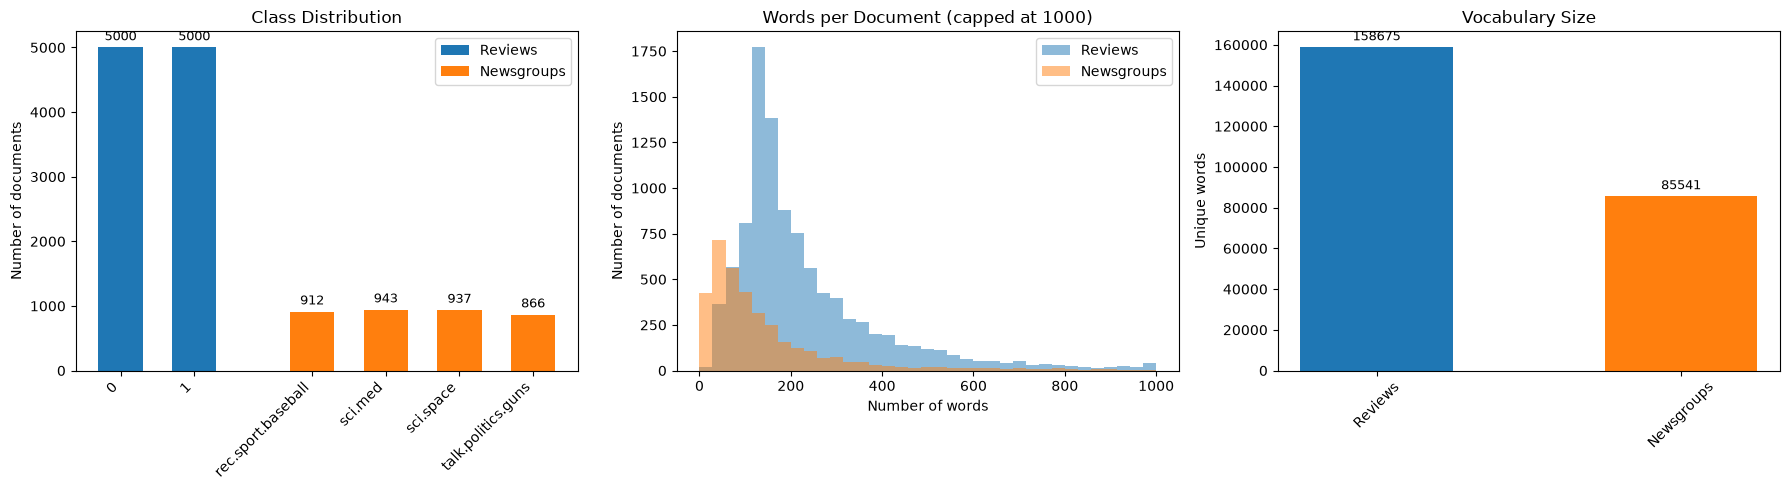


Reviews - first 3 training examples:
  [0] she has been catapulted from to with magic dust involved courtesy the year old matt but nothing is made of that except as an unexplained device new york city especially central park but also every oth...
  [1] chances are you ll think this movie is incredibly stupid the first time you watch it but if by chance you watch it a second and third and fourth and fifth time i m well into the hundreds by now you wi...
  [0] the first and only time i saw shades was during a sneakpreview it hadn t even been in premiere i remember there was someone of the directors staff there don t even remember who it was a belgian movie ...

Newsgroups - first 3 training examples:
  [rec.sport.baseball] judging by the way the reds pitchers have performed thus far it appears to me that the zone has been squeezed to the size of a grape...
  [talk.politics.guns] much of the dispute about the origin of the fire that destroyed the bd compound could be settled by examining

In [6]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS   # built-in list, no download needed
from nltk.stem import PorterStemmer                              # rule-based stemmer, no download needed

STOP_WORDS = set(ENGLISH_STOP_WORDS)
NEGATIONS = {"not", "no", "nor", "never", "cannot"}

# A tiny hand-made lemma dictionary (a real lemmatizer such as WordNet uses a much larger one)
LEMMA_DICT = {"was": "be", "were": "be", "is": "be", "are": "be", "am": "be",
              "movies": "movie", "films": "film", "actors": "actor", "characters": "character",
              "loved": "love", "hated": "hate", "liked": "like", "watched": "watch",
              "played": "play", "stopped": "stop", "better": "good", "worse": "bad",
              "best": "good", "worst": "bad", "scenes": "scene", "years": "year"}

stemmer = PorterStemmer()


def preprocess_text(text, stem=False, lemmatize=False, remove_stopwords=False, keep_negations=True):
    """
    Preprocess one document.

    Parameters:
    text (str): Input text to be preprocessed.
    stem (bool): Whether to apply stemming.
    lemmatize (bool): Whether to apply (dictionary-based) lemmatization.
    remove_stopwords (bool): Whether to remove stop-words.
    keep_negations (bool): If True, never remove the words in NEGATIONS even when removing stop-words.

    Returns:
    str: Preprocessed text (tokens joined by a single space).
    """
    # TODO: remove HTML tags such as <br /> (hint: re.sub(r"<[^>]+>", " ", text))
    text = re.sub(r"<[^>]+>", " ", text)
    # TODO: lowercase the text
    text = text.lower()
    # TODO: remove punctuation, digits and special characters (hint: re.sub)
    text = re.sub(r"[^a-z\s]", " ", text)
    # TODO: tokenize (hint: str.split)
    tokens = text.split()
    # TODO: optionally remove stop-words (respect keep_negations)
    if remove_stopwords:
        tokens = [token for token in tokens if token not in STOP_WORDS or token in NEGATIONS]
    # TODO: optionally lemmatize with LEMMA_DICT, then optionally stem with `stemmer`
    if lemmatize:
        tokens = [LEMMA_DICT.get(token, token) for token in tokens]
    if stem:
        tokens = [stemmer.stem(token) for token in tokens]
    # TODO: join the tokens back into a single string
    return " ".join(tokens)


def split_data(df, test_size=0.2, random_state=42):
    """Split a DataFrame (columns: text, label) into train/test sets, keeping class proportions."""
    return train_test_split(df["text"], df["label"], test_size=test_size,
                            random_state=random_state, stratify=df["label"])


def display_statistics(df, dataset_name):
    """
    Print statistics for a dataset: instances per class, average words per document, vocabulary size.

    Parameters:
    df (pandas.DataFrame): Dataset with 'text' and 'label' columns.
    dataset_name (str): Name used in the printed output.
    """
    # TODO: print the number of instances per class
    print(f"Number of instances per class in {dataset_name}:")
    print(df["label"].value_counts())
    # TODO: print the average number of words per document
    avg_words = df["text"].apply(lambda t: len(t.split())).mean()
    print(f"Average number of words per document in {dataset_name}: {avg_words:.2f}")
    # TODO: print the vocabulary size (number of unique words)
    vocab_size = df["text"].str.split().explode().nunique()
    print(f"Vocabulary size in {dataset_name}: {vocab_size}")


def plot_statistics(datasets):
    """
    Plot class distribution, document length distribution and vocabulary size.

    Parameters:
    datasets (dict): {dataset_name: DataFrame}
    """
    # TODO: create a figure with 3 subplots (use plt.subplots)
    #       1) class distribution of each dataset (bar plot)
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # 1) class distribution of each dataset (sequential grouped bars with counts)
    x_ticks = []
    x_labels = []
    current_pos = 0
    colors = plt.cm.tab10.colors

    for i, (name, df) in enumerate(datasets.items()):
        counts = df["label"].value_counts().sort_index()
        pos = np.arange(current_pos, current_pos + len(counts))
        bars = axes[0].bar(pos, counts.values, width=0.6, color=colors[i % len(colors)], label=name)
        axes[0].bar_label(bars, padding=3, fontsize=9)

        x_ticks.extend(pos)
        x_labels.extend([str(lbl) for lbl in counts.index])
        current_pos += len(counts) + 0.6  # spacing between datasets

    axes[0].set_title("Class Distribution")
    axes[0].set_xticks(x_ticks)
    axes[0].set_xticklabels(x_labels, rotation=45, ha="right")
    axes[0].set_ylabel("Number of documents")
    axes[0].legend()

    # 2) histogram of words per document for each dataset (range capped to focus on main distribution)
    for name, df in datasets.items():
        doc_lens = df["text"].str.split().str.len()
        axes[1].hist(doc_lens, bins=35, range=(0, 1000), alpha=0.5, label=name)
    axes[1].set_title("Words per Document (capped at 1000)")
    axes[1].set_xlabel("Number of words")
    axes[1].set_ylabel("Number of documents")
    axes[1].legend()

    # 3) vocabulary size of each dataset (bar plot)
    vocab_sizes = {
        name: df["text"].str.split().explode().nunique()
        for name, df in datasets.items()
    }
    bars3 = axes[2].bar(list(vocab_sizes.keys()), list(vocab_sizes.values()), color=colors[:len(vocab_sizes)], width=0.5)
    axes[2].bar_label(bars3, padding=3, fontsize=9)
    axes[2].set_title("Vocabulary Size")
    axes[2].set_ylabel("Unique words")
    axes[2].tick_params(axis="x", rotation=45)

    fig.tight_layout()
    plt.show()


# ---- Example usage ----
display_statistics(reviews_df, "Reviews")
display_statistics(news_df, "Newsgroups")
plot_statistics({"Reviews": reviews_df, "Newsgroups": news_df})

# Preprocess both datasets (try different flags and compare the vocabulary sizes!)
reviews_clean = reviews_df.copy()
news_clean = news_df.copy()
reviews_clean["text"] = reviews_clean["text"].apply(lambda t: preprocess_text(t, stem=False, lemmatize=False))
news_clean["text"] = news_clean["text"].apply(lambda t: preprocess_text(t, stem=False, lemmatize=False))

X_train_reviews, X_test_reviews, y_train_reviews, y_test_reviews = split_data(reviews_clean)
X_train_news, X_test_news, y_train_news, y_test_news = split_data(news_clean)

print("\nReviews - first 3 training examples:")
for text, label in zip(X_train_reviews.head(3), y_train_reviews.head(3)):
    print(f"  [{label}] {text[:200]}...")
print("\nNewsgroups - first 3 training examples:")
for text, label in zip(X_train_news.head(3), y_train_news.head(3)):
    print(f"  [{label}] {text[:200]}...")

In [ ]:
preprocess_text(text, stem=True, lemmatize=False, remove_stopwords=false)
print("vocabulary size after preprocessing Reviews:", reviews_clean["text"].str.split().explode().nunique())



## Exercise 2: Feature Extraction with TF-IDF

**Goal:** Represent text numerically using TF-IDF and understand how TF-IDF scoring works.

A classifier cannot read words, it needs numbers. TF-IDF turns every document into a vector with one dimension per vocabulary word. It highlights words that are important in a specific document but less common across the entire dataset.

**TF-IDF Explanation**:
TF-IDF stands for **Term Frequency-Inverse Document Frequency**. It is computed as follows:

- **Term Frequency (TF)**: Measures the frequency of a term in a document.
  $$ \text{TF}(w, d) = \frac{\text{count of } w \text{ in } d}{\text{total words in } d} $$

- **Inverse Document Frequency (IDF)**: Measures how unique a term is across all documents.
  $$ \text{IDF}(w) = \log \frac{N}{\text{DF}(w)} $$
  where $ N $ is the total number of documents, and $ \text{DF}(w) $ is the document frequency of $ w $.

Thus:
$$ \text{TF-IDF}(w, d) = \text{TF}(w, d) \times \text{IDF}(w) $$

(Note: `sklearn` uses a slightly different, *smoothed* IDF, $\log\frac{1+N}{1+\text{DF}(w)}+1$, and L2-normalizes every document vector, so its numbers will not exactly match a hand computation. The ideas are the same. The appendix at the end of the notebook shows the textbook computation by hand.)

We will use `sklearn.feature_extraction.text.TfidfVectorizer` to calculate TF-IDF.

#### Code Explanation:
- **`TfidfVectorizer`**:
  - **Input**: Raw text data.
  - **Output**: Sparse matrix of TF-IDF scores (one row per document, one column per vocabulary word).
  - **Parameters**: `max_features` (limits vocabulary size), `ngram_range` (for n-grams), `stop_words` (removes common words), `sublinear_tf` (uses $1+\log(\text{tf})$ instead of the raw count).
- **`fit` vs `transform`**: `fit` learns the vocabulary and the IDF values, `transform` only applies them.

#### Task:
1. **TF-IDF calculation**: implement `get_tfidf_features` and apply it to each dataset. The vectorizer must be **fitted on the training set only**.
2. **Print the TF-IDF values** of a few reviews/posts with `print_tfidf_vector`.
3. **New document transformation**: use the fitted `TfidfVectorizer` to transform a new, unseen document into a TF-IDF vector. What happens to words that are not in the vocabulary?
4. **Parameter study**: compare the vocabulary size and the matrix shape for different values of `max_features` and `ngram_range`.

#### Questions to answer (in a markdown cell below your code):
- What role do the parameters `max_features` and `ngram_range` play in the vectorization? What are the trade-offs of using bigrams such as `"not good"`?
- Why must the vectorizer be fitted on the training set only? What kind of mistake would happen if you fitted it on train + test (hint: *data leakage*)?
- Why is the matrix stored as a *sparse* matrix? Compute its density (fraction of non-zero entries).

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer


def get_tfidf_features(X_train, X_test, max_features=5000, ngram_range=(1, 1), sublinear_tf=False):
    """
    Extract TF-IDF features from training and test text data.

    Parameters:
    X_train (pd.Series): Training text data.
    X_test (pd.Series): Test text data.
    max_features (int): Maximum number of features to keep in the vocabulary.
    ngram_range (tuple): Lower and upper boundary of the n-gram range, (1, 1) = unigrams only.
    sublinear_tf (bool): Apply sublinear term-frequency scaling if True.

    Returns:
    tuple: (train_tfidf, test_tfidf, tfidf)
        - train_tfidf (sparse matrix): TF-IDF matrix of the training data.
        - test_tfidf (sparse matrix): TF-IDF matrix of the test data.
        - tfidf (TfidfVectorizer): Fitted vectorizer (vocabulary and IDF values).

    Example:
    >>> X_train = pd.Series(["This is a sample sentence.", "Another example sentence."])
    >>> X_test = pd.Series(["This is a test sentence."])
    >>> train_tfidf, test_tfidf, tfidf = get_tfidf_features(X_train, X_test)
    >>> train_tfidf.shape
    (2, 7)   # 2 documents, 7 unique words
    """
    # TODO: create the TfidfVectorizer with the given parameters
    tfidf = TfidfVectorizer(max_features=max_features, ngram_range=ngram_range, sublinear_tf=sublinear_tf)
    # TODO: fit it on X_train ONLY and transform X_train
    train_tfidf = tfidf.fit_transform(X_train)
    # TODO: transform X_test with the already-fitted vectorizer (no refitting!)
    test_tfidf = tfidf.transform(X_test)
    return train_tfidf, test_tfidf, tfidf


def print_tfidf_vector(sent, sent_tfidf_vector, feature_names):
    """
    Print the TF-IDF value of each word of a sentence, sorted from highest to lowest.

    Parameters:
    sent (str): The sentence whose TF-IDF values are printed.
    sent_tfidf_vector (numpy.ndarray): Dense TF-IDF vector of the sentence, shape (1, n_features).
    feature_names (array-like): Vocabulary words, in the same order as the vector columns.

    Expected output format:
    Words in sentence:
    ['this', 'is', 'a', 'sample', 'sentence']
    Sorted words by TF-IDF score (highest to lowest) and vocabulary presence:
    Word: sample, TF-IDF: 0.7000, In Vocab: True
    Word: sentence, TF-IDF: 0.5000, In Vocab: True
    Word: a, TF-IDF: 0.0000, In Vocab: False
    """
    # TODO: split the sentence into words
    words = sent.split()
    # TODO: for every word, find its TF-IDF value (0 if the word is not in feature_names)
    word_scores = []
    for word in words:
        if word in feature_names:
            index = np.where(feature_names == word)[0][0]
            score = sent_tfidf_vector[0, index]
            in_vocab = True
        else:
            score = 0.0
            in_vocab = False
        word_scores.append((word, score, in_vocab))
    # TODO: sort the words by score (descending) and print them with the "In Vocab" flag
    word_scores.sort(key=lambda x: x[1], reverse=True)
    for word, score, in_vocab in word_scores:
        print(f"Word: {word}, TF-IDF: {score:.4f}, In Vocab: {in_vocab}")


def transform_new_document(new_document, tfidf_vectorizer):
    """
    Transform a new document into a dense TF-IDF vector with a fitted TfidfVectorizer.

    Parameters:
    new_document (str): The new document.
    tfidf_vectorizer (TfidfVectorizer): A fitted vectorizer.

    Returns:
    numpy.ndarray: Dense TF-IDF vector of shape (1, n_features).
    """
    # TODO: transform the document (remember: transform expects a list of documents)
    sparse_vector = tfidf_vectorizer.transform([new_document])
    # TODO: convert the sparse result to a dense array
    dense_vector = sparse_vector.toarray()
    return dense_vector
    


# ---- Example usage (uncomment once your functions are implemented) ----
train_tfidf_reviews, test_tfidf_reviews, tfidf_reviews = get_tfidf_features(X_train_reviews, X_test_reviews)
train_tfidf_news, test_tfidf_news, tfidf_news = get_tfidf_features(X_train_news, X_test_news)

feature_names_reviews = tfidf_reviews.get_feature_names_out()
print(feature_names_reviews[:50])
print("Train matrix shape:", train_tfidf_reviews.shape)

print("The TF-IDF values of the first training review:")
print_tfidf_vector(X_train_reviews.iloc[0], train_tfidf_reviews[0].toarray(), feature_names_reviews)

# Transform a new document
new_sent = "I absolutely loved this movie, the acting was brilliant and the plot was exciting!"
new_vec = transform_new_document(new_sent, tfidf_reviews)
print_tfidf_vector(new_sent, new_vec, feature_names_reviews)

# TODO: parameter study - loop over several max_features / ngram_range values and report the shapes
for max_features in [1000, 5000, 10000]:
    for ngram_range in [(1, 1), (1, 2), (1, 3)]:
        train_tfidf, test_tfidf, tfidf = get_tfidf_features(X_train_reviews, X_test_reviews, max_features=max_features, ngram_range=ngram_range)
        print(f"max_features: {max_features}, ngram_range: {ngram_range}")
        print(f"Train matrix shape: {train_tfidf.shape}")
        print(f"Test matrix shape: {test_tfidf.shape}")
        print()

['aaron' 'abandoned' 'abc' 'abilities' 'ability' 'able' 'about' 'above'
 'absence' 'absent' 'absolute' 'absolutely' 'absurd' 'abuse' 'abused'
 'abusive' 'academy' 'accent' 'accents' 'accept' 'acceptable' 'accepted'
 'access' 'accident' 'accidentally' 'accompanied' 'accomplished'
 'according' 'account' 'accounts' 'accuracy' 'accurate' 'accused'
 'achieve' 'achieved' 'achievement' 'across' 'act' 'acted' 'acting'
 'action' 'actions' 'activities' 'actor' 'actors' 'actress' 'actresses'
 'acts' 'actual' 'actually']
Train matrix shape: (8000, 5000)
The TF-IDF values of the first training review:
Word: lucy, TF-IDF: 0.2832, In Vocab: True
Word: lucy, TF-IDF: 0.2832, In Vocab: True
Word: device, TF-IDF: 0.2442, In Vocab: True
Word: device, TF-IDF: 0.2442, In Vocab: True
Word: matt, TF-IDF: 0.2435, In Vocab: True
Word: matt, TF-IDF: 0.2435, In Vocab: True
Word: the, TF-IDF: 0.1667, In Vocab: True
Word: the, TF-IDF: 0.1667, In Vocab: True
Word: the, TF-IDF: 0.1667, In Vocab: True
Word: the, TF-ID

## Exercise 3: Logistic Regression with Detailed Equations

**Goal:** Train logistic regression for the binary and multiclass cases, understanding each step and the underlying equations.

#### Logistic Regression for Binary Classification

For binary classification, logistic regression models the probability that a given input $x$ belongs to class 1. The model predicts:
$$ P(y = 1 | x) = \sigma(w^T x + b) $$
where:
- $w$ is the weight vector (one weight per vocabulary word),
- $x$ is the feature vector (TF-IDF representation),
- $b$ is the bias term,
- $ \sigma(z) = \frac{1}{1 + e^{-z}} $ is the sigmoid function.

The prediction is class 1 if $P(y=1|x) \geq 0.5$, i.e. if $w^T x + b \geq 0$.

The **cross-entropy loss** for binary logistic regression is:
$$ L(y, \hat{y}) = -\left( y \log(\hat{y}) + (1 - y) \log(1 - \hat{y}) \right) $$
where $ \hat{y} = P(y = 1 | x) $.

#### Logistic Regression for Multiclass Classification

For multiclass, logistic regression uses the **softmax function**:
$$ P(y = k | x) = \frac{e^{w_k^T x + b_k}}{\sum_{j=1}^{K} e^{w_j^T x + b_j}} $$
where $K$ is the number of classes (here $K = 4$ for the newsgroups: `rec.sport.baseball`, `sci.med`, `sci.space`, `talk.politics.guns`). The model learns one weight vector $w_k$ per class, and the predicted probabilities sum to 1.

The **cross-entropy loss** for multiclass is:
$$ L(y, \hat{y}) = -\sum_{k=1}^{K} y_k \log(\hat{y}_k) $$
where $y_k$ is a binary indicator for the true class.

In practice `sklearn` minimizes this loss plus an L2 penalty $\frac{1}{2C}\|w\|^2$, where **`C`** is the *inverse* regularization strength (smaller `C` = stronger regularization).

#### Code Explanation:
- **`LogisticRegression`**:
  - For binary: `LogisticRegression(solver='liblinear')`
  - For multiclass: `LogisticRegression(solver='lbfgs')`. With 3+ classes and the `lbfgs` solver, `sklearn` automatically fits the **multinomial (softmax)** model, so you do not need to set `multi_class` (that parameter is deprecated in recent versions).
  - **Input**: TF-IDF features, labels.
  - **Output**: `predict` gives labels, `predict_proba` gives class probabilities, `coef_` and `intercept_` give $w$ and $b$.

#### Task:
1. Train an `sklearn` logistic regression model on the **reviews** dataset (binary).
2. Train an `sklearn` logistic regression model on the **newsgroups** dataset (multiclass).
3. Report precision, recall and F1-score for each dataset (for the multiclass case use the `macro` average).
4. **Check the equations yourself**: implement `sigmoid` and `softmax`, recompute the probability of one test document from `coef_` and `intercept_` using your functions, and verify that it matches `predict_proba`.

#### Questions to answer (in a markdown cell below your code):
- What are the shapes of `coef_` and `intercept_` in the binary case and in the multiclass case? Why?
- A review gets $P(y=1|x) = 0.51$. Is the model confident? What does that tell you about using probabilities, not only labels?

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score


def binary_logistic_regression(X_train, y_train, X_test, y_test):
    """
    Train a binary logistic regression model.

    Parameters:
    X_train (sparse matrix): Training features.   y_train (array-like): Training labels.
    X_test (sparse matrix): Test features.        y_test (array-like): Test labels.

    Returns:
    tuple: (model, y_pred, y_prob)
        model (LogisticRegression): Trained model.
        y_pred (np.ndarray): Predicted labels on the test set.
        y_prob (np.ndarray): Predicted probability of class 1 on the test set.
    """
    # TODO:  create LogisticRegression(solver='liblinear'), fit on the training data
    model = LogisticRegression(solver='liblinear')
    model.fit(X_train, y_train)
    # TODO: predict labels and the probability of class 1 on the test set
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    return model, y_pred, y_prob


def multiclass_logistic_regression(X_train, y_train, X_test, y_test):
    """
    Train a multiclass (softmax) logistic regression model.

    Returns:
    tuple: (model, y_pred, y_prob)
        model (LogisticRegression): Trained model.
        y_pred (np.ndarray): Predicted labels on the test set.
        y_prob (np.ndarray): Predicted probabilities of shape (n_test, n_classes).
    """
    # TODO: create LogisticRegression(solver='lbfgs', max_iter=1000), fit on the training data
    model = LogisticRegression(solver='lbfgs', max_iter=1000)
    model.fit(X_train, y_train)
    # TODO: predict labels and class probabilities on the test set
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)
    return model, y_pred, y_prob


def sigmoid(z):
    """Sigmoid function sigma(z) = 1 / (1 + exp(-z))."""
    # TODO
    return 1 / (1 + np.exp(-z))


def softmax(scores):
    """Softmax over the last axis. scores has shape (n_samples, n_classes). Use the max-subtraction trick for numerical stability."""
    # TODO
    exp_scores = np.exp(scores - np.max(scores, axis=1, keepdims=True))
    return exp_scores / np.sum(exp_scores, axis=1, keepdims=True)


def report_metrics(y_true, y_pred, average="binary"):
    """Print accuracy, precision, recall and F1 (average='binary' or 'macro')."""
    # TODO: print the four metrics with 4 decimals
    print(f"Accuracy: {accuracy_score(y_true, y_pred):.4f}")
    print(f"Precision: {precision_score(y_true, y_pred, average=average):.4f}")
    print(f"Recall: {recall_score(y_true, y_pred, average=average):.4f}")
    print(f"F1: {f1_score(y_true, y_pred, average=average):.4f}")


# ---- Example usage (uncomment once your functions are implemented) ----
bin_model, bin_pred, bin_prob = binary_logistic_regression(train_tfidf_reviews, y_train_reviews, test_tfidf_reviews, y_test_reviews)
multi_model, multi_pred, multi_prob = multiclass_logistic_regression(train_tfidf_news, y_train_news, test_tfidf_news, y_test_news)

print("Binary (reviews):");      report_metrics(y_test_reviews, bin_pred, average="binary")
print("Multiclass (newsgroups):");  report_metrics(y_test_news, multi_pred, average="macro")

# TODO: verify the equations - recompute P(y=1|x) (binary) and the softmax probabilities (multiclass)
#       of test document 0 from model.coef_ / model.intercept_ and compare with predict_proba.

# 1. Binary: P(y=1|x) = sigmoid(w^T * x + b)
x0_bin = test_tfidf_reviews[0]
z_bin = (x0_bin @ bin_model.coef_.T).item() + bin_model.intercept_.item()
prob_bin_manual = sigmoid(z_bin)
prob_bin_sklearn = bin_model.predict_proba(x0_bin)[0, 1]

print("\n--- Binary Equation Verification (Test Doc 0) ---")
print(f"Manual P(y=1|x) = sigmoid(w^T x + b): {prob_bin_manual:.6f}")
print(f"sklearn predict_proba P(y=1|x):       {prob_bin_sklearn:.6f}")
print(f"Match: {np.isclose(prob_bin_manual, prob_bin_sklearn)}")

# 2. Multiclass: P(y=k|x) = softmax(W * x + b)
x0_multi = test_tfidf_news[0]
scores_multi = np.asarray(x0_multi @ multi_model.coef_.T) + multi_model.intercept_
prob_multi_manual = softmax(scores_multi)[0]
prob_multi_sklearn = multi_model.predict_proba(x0_multi)[0]

print("\n--- Multiclass Softmax Verification (Test Doc 0) ---")
for k, class_name in enumerate(multi_model.classes_):
    print(f"Class '{class_name}': Manual = {prob_multi_manual[k]:.6f} | sklearn = {prob_multi_sklearn[k]:.6f}")
print(f"Match: {np.allclose(prob_multi_manual, prob_multi_sklearn)}")


Binary (reviews):
Accuracy: 0.8675
Precision: 0.8585
Recall: 0.8800
F1: 0.8691
Multiclass (newsgroups):
Accuracy: 0.9044
Precision: 0.9053
Recall: 0.9040
F1: 0.9043

--- Binary Equation Verification (Test Doc 0) ---
Manual P(y=1|x) = sigmoid(w^T x + b): 0.293140
sklearn predict_proba P(y=1|x):       0.293140
Match: True

--- Multiclass Softmax Verification (Test Doc 0) ---
Class 'rec.sport.baseball': Manual = 0.110885 | sklearn = 0.110885
Class 'sci.med': Manual = 0.693280 | sklearn = 0.693280
Class 'sci.space': Manual = 0.097028 | sklearn = 0.097028
Class 'talk.politics.guns': Manual = 0.098807 | sklearn = 0.098807
Match: True


## Exercise 4: Model Evaluation and Cross-Validation

**Goal:** Measure how well your models really perform, and how much you can trust that number.

A single accuracy value on a single split can be misleading: the split may be lucky or unlucky, and accuracy hides *which* classes the model confuses. In this exercise you evaluate in three complementary ways.

#### 1. Evaluation on the test set
Train on the training data, predict on the held-out test data, and compute:
- **Accuracy**: fraction of correct predictions.
- **Precision**: $\frac{TP}{TP+FP}$, of the documents predicted as class $k$, how many truly are.
- **Recall**: $\frac{TP}{TP+FN}$, of the documents truly in class $k$, how many were found.
- **F1-score**: harmonic mean of precision and recall, $\frac{2PR}{P+R}$.
- **Confusion matrix**: rows = true class, columns = predicted class. It shows *which* classes get confused.

For the multiclass case, per-class scores are combined with an average: **macro** (unweighted mean over classes), **weighted** (mean weighted by class size) or **micro** (computed from global counts).

#### 2. K-fold cross-validation
Split the training data into $k$ folds (here $k = 5$). Train on $k-1$ folds, validate on the remaining one, and repeat so every fold is used once for validation. The mean and standard deviation of the scores tell you how stable the model is.

**Important:** if you vectorize the text *before* cross-validation, the vectorizer has seen the validation fold when learning the vocabulary and IDF values, which is a subtle form of *data leakage*. To avoid it, put the `TfidfVectorizer` and the classifier together in an `sklearn` **`Pipeline`**, and give the pipeline to `cross_validate`: the vectorizer is then refitted on the training folds only, at every iteration.

#### Task:
1. Implement `evaluate_model`: train a model, print the `classification_report` and the confusion matrix, for both datasets.
2. Implement `plot_confusion_matrix` (hint: `ConfusionMatrixDisplay.from_predictions`).
3. Implement `evaluate_cross_validation` with a `Pipeline` and `cross_validate`, using `accuracy`, `precision`, `recall`, `f1` (macro versions for multiclass). Report mean $\pm$ standard deviation for each metric.

#### Questions to answer (in a markdown cell below your code):
- Which pair of newsgroups is confused the most? Look at a few misclassified posts: can you understand why?
- Compare the cross-validation mean with the test-set score. Are they consistent? What does a large standard deviation indicate?
- When would accuracy be a misleading metric? Would you prefer macro-F1 or accuracy if one class represented 95% of the data?

Binary Logistic Regression on Test Set:
              precision    recall  f1-score   support

           0     0.8769    0.8550    0.8658      1000
           1     0.8585    0.8800    0.8691      1000

    accuracy                         0.8675      2000
   macro avg     0.8677    0.8675    0.8675      2000
weighted avg     0.8677    0.8675    0.8675      2000



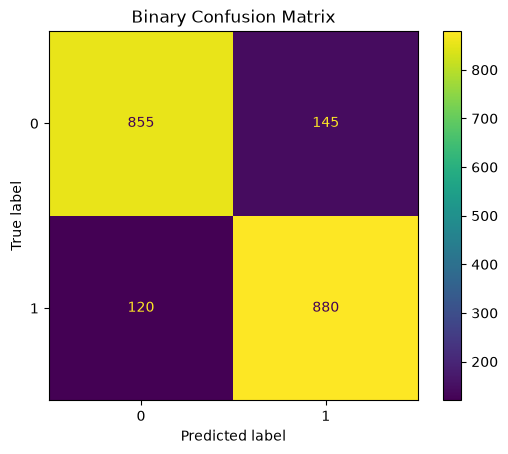

Multiclass Logistic Regression on Test Set:
                    precision    recall  f1-score   support

rec.sport.baseball     0.8973    0.9121    0.9046       182
           sci.med     0.8850    0.9365    0.9100       189
         sci.space     0.9171    0.8830    0.8997       188
talk.politics.guns     0.9217    0.8844    0.9027       173

          accuracy                         0.9044       732
         macro avg     0.9053    0.9040    0.9043       732
      weighted avg     0.9050    0.9044    0.9043       732



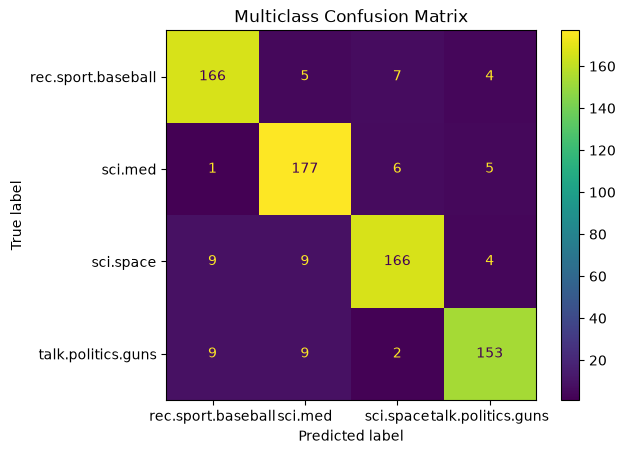

5-Fold Cross-Validation (Binary):
  accuracy: 0.8661 +/- 0.0099
  precision: 0.8551 +/- 0.0100
  recall: 0.8818 +/- 0.0111
  f1: 0.8682 +/- 0.0098
5-Fold Cross-Validation (Multiclass):
  accuracy: 0.9022 +/- 0.0169
  precision_macro: 0.9032 +/- 0.0174
  recall_macro: 0.9019 +/- 0.0168
  f1_macro: 0.9020 +/- 0.0172


In [12]:
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer


def plot_confusion_matrix(y_true, y_pred, title="Confusion matrix"):
    """Plot a confusion matrix for the given true and predicted labels."""
    # TODO: use ConfusionMatrixDisplay.from_predictions and plt.show()
    disp = ConfusionMatrixDisplay.from_predictions(y_true, y_pred)
    disp.ax_.set_title(title)
    plt.show()


def evaluate_model(X_train_tfidf, y_train, X_test_tfidf, y_test, num_classes=2):
    """
    Train a logistic regression model and evaluate it on the test set.

    Parameters:
    X_train_tfidf, X_test_tfidf: TF-IDF features of the training and test sets.
    y_train, y_test: Training and test labels.
    num_classes (int): 2 for binary, > 2 for multiclass.

    Returns:
    None: prints the classification report and shows the confusion matrix.
    """
    if num_classes == 2:
        model = LogisticRegression(solver="liblinear")
        print("Binary Logistic Regression on Test Set:")
        title = "Binary Confusion Matrix"
    else:
        model = LogisticRegression(solver="lbfgs", max_iter=1000)
        print("Multiclass Logistic Regression on Test Set:")
        title = "Multiclass Confusion Matrix"

    # TODO: fit the model and predict on the test set
    model.fit(X_train_tfidf, y_train)
    y_pred = model.predict(X_test_tfidf)

    # TODO: print classification_report (precision, recall, F1 per class + averages)
    print(classification_report(y_test, y_pred, digits=4))

    # TODO: plot the confusion matrix with plot_confusion_matrix
    plot_confusion_matrix(y_test, y_pred, title=title)


def evaluate_cross_validation(X_text, y, num_classes=2, num_folds=5, max_features=5000, ngram_range=(1, 1)):
    """
    Cross-validate a TF-IDF + logistic regression Pipeline on RAW/cleaned text (not on pre-computed features).

    Parameters:
    X_text (pd.Series): Training texts.   y (pd.Series): Training labels.
    num_classes (int): 2 for binary, > 2 for multiclass.
    num_folds (int): Number of cross-validation folds.

    Returns:
    dict: the dictionary returned by cross_validate.
    """
    # TODO: build a Pipeline([("tfidf", TfidfVectorizer(...)), ("clf", LogisticRegression(...))])
    clf = LogisticRegression(solver="liblinear") if num_classes == 2 else LogisticRegression(solver="lbfgs", max_iter=1000)
    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(max_features=max_features, ngram_range=ngram_range)),
        ("clf", clf)
    ])

    # TODO: choose the scoring dict: binary -> accuracy / precision / recall / f1
    #                                multiclass -> accuracy / precision_macro / recall_macro / f1_macro
    scoring = ["accuracy", "precision", "recall", "f1"] if num_classes == 2 else ["accuracy", "precision_macro", "recall_macro", "f1_macro"]

    # TODO: run cross_validate with StratifiedKFold(num_folds, shuffle=True, random_state=42)
    cv = StratifiedKFold(n_splits=num_folds, shuffle=True, random_state=42)
    scores = cross_validate(pipeline, X_text, y, cv=cv, scoring=scoring)

    # TODO: print "mean +/- std" for every metric
    print(f"{num_folds}-Fold Cross-Validation ({'Binary' if num_classes == 2 else 'Multiclass'}):")
    for metric in scoring:
        val = scores[f"test_{metric}"]
        print(f"  {metric}: {val.mean():.4f} +/- {val.std():.4f}")
    return scores


# ---- Example usage (uncomment once your functions are implemented) ----
evaluate_model(train_tfidf_reviews, y_train_reviews, test_tfidf_reviews, y_test_reviews, num_classes=2)
evaluate_model(train_tfidf_news, y_train_news, test_tfidf_news, y_test_news, num_classes=4)

cv_reviews = evaluate_cross_validation(X_train_reviews, y_train_reviews, num_classes=2)
cv_news = evaluate_cross_validation(X_train_news, y_train_news, num_classes=4)


## Exercise 5: Model Interpretation, Hyperparameters and Error Analysis

**Goal:** Go beyond the score: understand *why* the model predicts what it predicts, tune it sensibly, and study where it fails.

One big advantage of logistic regression over many other models is that it is **interpretable**: the prediction is $w^T x + b$, so each weight $w_j$ tells you how much the presence of word $j$ pushes the prediction towards a class. A large positive weight on `"excellent"` pushes towards *positive*, a large negative weight on `"awful"` pushes towards *negative*.

#### Task:
1. **Most influential words.**
   - Binary case: list the 10 words with the largest positive weights and the 10 with the largest negative weights.
   - Multiclass case: for each of the 4 newsgroups, list the 10 words with the largest weights for that class.
   - Plot them as horizontal bar charts.
2. **Regularization.** Train models for several values of `C` (e.g. `0.01, 0.1, 1, 10, 100`). Plot train and validation accuracy against `C` (log scale on the x-axis). Which `C` generalizes best? What happens when `C` is very small? Very large?
3. **Unigrams vs bigrams.** Compare `ngram_range=(1, 1)` with `ngram_range=(1, 2)` on the reviews. Then check the effect on the sentences:
   - `"not good at all"` and `"not bad at all"`
   - `"good"` and `"bad"`

   Can a unigram model tell the difference? Do the bigrams `"not good"` and `"not bad"` appear among the most influential features?
4. **Error analysis.** Collect the misclassified test documents, print 10 of them with their true label, predicted label and predicted probability, and group the errors into categories (mixed or sarcastic opinions, negation, very short posts, overlapping topics such as `sci.med` vs `sci.space`, ...).

#### Questions to answer (in a markdown cell below your code):
- Do the most influential words make sense? Do you find any suspicious word (a word that is predictive but not meaningful)?
- What is the effect of the regularization parameter on the weights and on overfitting?
- Suggest two concrete improvements for the errors you found (e.g. a different preprocessing, n-grams, more data, a different model) and explain why each should help.

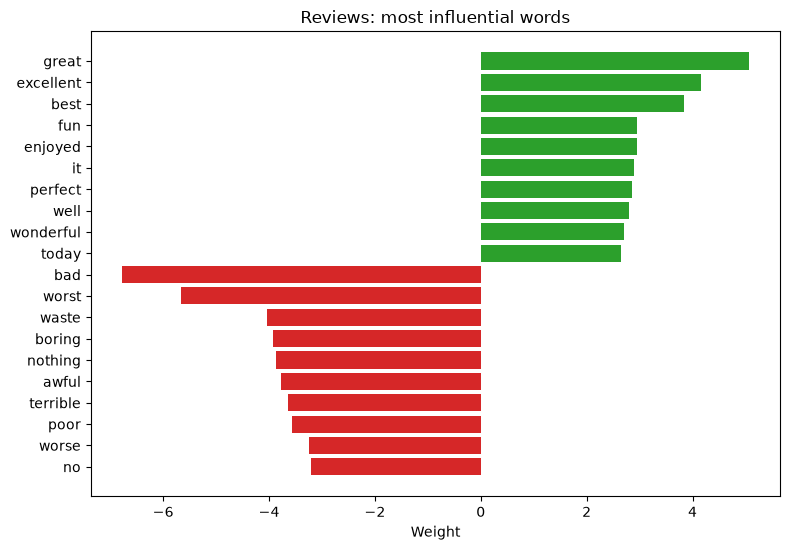

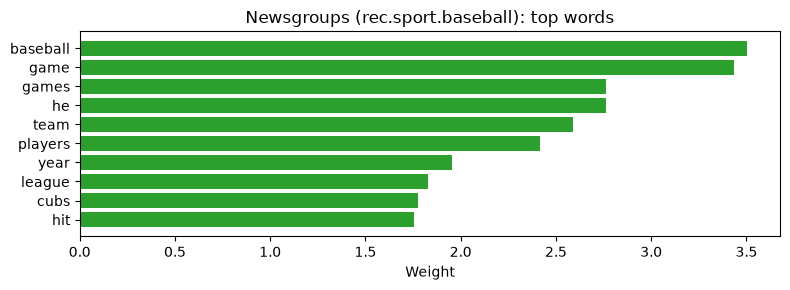

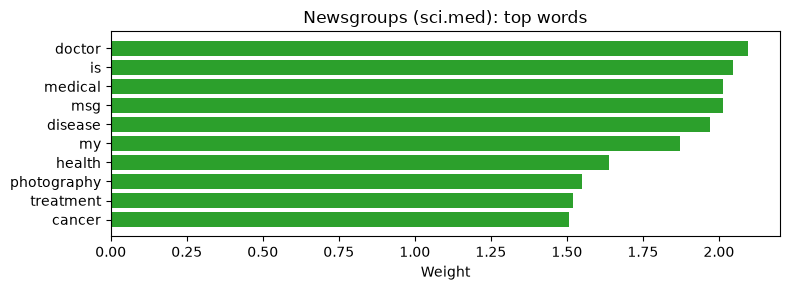

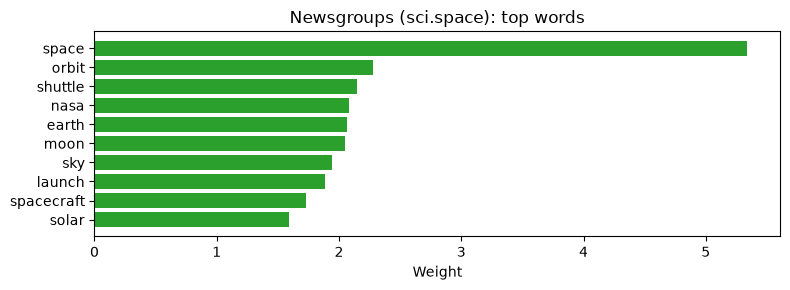

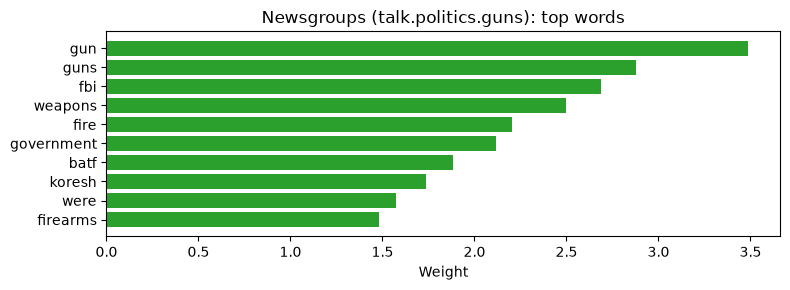

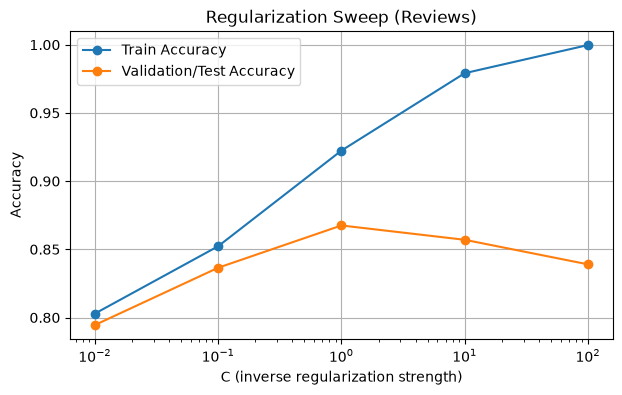


ngram_range=(1, 1) -> Test Accuracy: 0.8675
  P(positive) = 0.4035 | "not good at all"
  P(positive) = 0.0035 | "not bad at all"
  P(positive) = 0.8603 | "good"
  P(positive) = 0.0014 | "bad"

ngram_range=(1, 2) -> Test Accuracy: 0.8710
  P(positive) = 0.1330 | "not good at all"
  P(positive) = 0.0427 | "not bad at all"
  P(positive) = 0.7966 | "good"
  P(positive) = 0.0023 | "bad"
True: 0 | Pred: 1, P=0.6241 | Text: there is a dvd published in the uk in code hrgd on the cover no asin vfc on the disk no ifpi code in the inner rim proba...
True: 1 | Pred: 0, P=0.4335 | Text: what i like about spoilers teenager holly tyler amanda bynes goes to live with older sister valerie jennie garth to avoi...
True: 0 | Pred: 1, P=0.5190 | Text: i felt that the movie skammen directed by ingmar bergman was very dry it shows the things people will do to survive duri...
True: 1 | Pred: 0, P=0.4060 | Text: nazarin is some kind of saint he wants to live in life exactly how christ taught man to do but it 

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score


def top_features_binary(model, feature_names, n=10):
    """
    Return the n words with the largest positive weights and the n with the largest negative weights.

    Returns:
    tuple: (top_positive, top_negative), each a list of (word, weight) pairs.
    """
    # TODO: use model.coef_[0] and np.argsort
    coef = model.coef_[0]
    sorted_idx = np.argsort(coef)
    top_negative = [(feature_names[i], coef[i]) for i in sorted_idx[:n]]
    top_positive = [(feature_names[i], coef[i]) for i in sorted_idx[-n:][::-1]]
    return top_positive, top_negative


def top_features_multiclass(model, feature_names, n=10):
    """
    Return the n words with the largest weights for each class.

    Returns:
    dict: {class_name: [(word, weight), ...]}
    """
    # TODO: loop over model.classes_ and the rows of model.coef_
    top_by_class = {}
    for i, class_name in enumerate(model.classes_):
        row = model.coef_[i]
        sorted_idx = np.argsort(row)[-n:][::-1]
        top_by_class[class_name] = [(feature_names[j], row[j]) for j in sorted_idx]
    return top_by_class


def plot_top_features(top_features, title):
    """Plot (word, weight) pairs as a horizontal bar chart."""
    # TODO
    words = [w for w, _ in top_features]
    weights = [wt for _, wt in top_features]
    colors = ["#2ca02c" if wt > 0 else "#d62728" for wt in weights]
    plt.figure(figsize=(8, max(3, len(words) * 0.28)))
    plt.barh(words, weights, color=colors)
    plt.title(title)
    plt.xlabel("Weight")
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()


def regularization_sweep(X_train_tfidf, y_train, X_val_tfidf, y_val, C_values, solver="liblinear"):
    """
    Train one model per value of C and record train / validation accuracy.

    Returns:
    pd.DataFrame with columns: C, train_acc, val_acc
    """
    # TODO: loop over C_values, fit LogisticRegression(C=C, solver=solver, max_iter=1000)
    # TODO: collect the accuracies in a DataFrame
    train_accs, val_accs = [], []
    for C in C_values:
        clf = LogisticRegression(C=C, solver=solver, max_iter=1000).fit(X_train_tfidf, y_train)
        train_accs.append(accuracy_score(y_train, clf.predict(X_train_tfidf)))
        val_accs.append(accuracy_score(y_val, clf.predict(X_val_tfidf)))
    return pd.DataFrame({"C": C_values, "train_acc": train_accs, "val_acc": val_accs})


def compare_ngrams(X_train, y_train, X_test, y_test, test_sentences):
    """
    Train a model with unigrams and a model with unigrams+bigrams, print the test accuracy of both
    and their predicted P(positive) on each sentence of test_sentences.
    """
    # TODO: for ngram_range in [(1, 1), (1, 2)]: vectorize, train, evaluate, predict on test_sentences
    for ngram_range in [(1, 1), (1, 2)]:
        pipe = Pipeline([
            ("tfidf", TfidfVectorizer(max_features=5000, ngram_range=ngram_range)),
            ("clf", LogisticRegression(solver="liblinear"))
        ])
        pipe.fit(X_train, y_train)
        acc = pipe.score(X_test, y_test)
        print(f"\nngram_range={ngram_range} -> Test Accuracy: {acc:.4f}")
        probs = pipe.predict_proba(test_sentences)[:, 1]
        for sentence, prob in zip(test_sentences, probs):
            print(f"  P(positive) = {prob:.4f} | \"{sentence}\"")


def error_analysis(X_test, y_test, y_pred, y_prob=None, n=10):
    """
    Print n misclassified documents with their true label, predicted label and (optionally) confidence.
    """
    # TODO: find the indices where y_test != y_pred and print n of them
    y_test_arr = np.array(y_test)
    y_pred_arr = np.array(y_pred)
    misclassified = np.where(y_test_arr != y_pred_arr)[0][:n]
    for idx in misclassified:
        text = str(X_test.iloc[idx]).replace("\n", " ")[:120]
        true_lbl = y_test_arr[idx]
        pred_lbl = y_pred_arr[idx]
        conf = f", P={y_prob[idx]:.4f}" if y_prob is not None else ""
        print(f"True: {true_lbl} | Pred: {pred_lbl}{conf} | Text: {text}...")


# ---- Example usage (uncomment once your functions are implemented; reuse variables from Exercises 2-3) ----
top_pos, top_neg = top_features_binary(bin_model, feature_names_reviews)
plot_top_features(top_pos + top_neg, "Reviews: most influential words")

feature_names_news = tfidf_news.get_feature_names_out()
top_news = top_features_multiclass(multi_model, feature_names_news)
for cls, feats in top_news.items():
    plot_top_features(feats, f"Newsgroups ({cls}): top words")

results = regularization_sweep(train_tfidf_reviews, y_train_reviews, test_tfidf_reviews, y_test_reviews, [0.01, 0.1, 1, 10, 100])
# TODO: plot results (train_acc and val_acc against C, log x-axis)
plt.figure(figsize=(7, 4))
plt.plot(results["C"], results["train_acc"], marker="o", label="Train Accuracy")
plt.plot(results["C"], results["val_acc"], marker="o", label="Validation/Test Accuracy")
plt.xscale("log")
plt.xlabel("C (inverse regularization strength)")
plt.ylabel("Accuracy")
plt.title("Regularization Sweep (Reviews)")
plt.legend()
plt.grid(True)
plt.show()

compare_ngrams(X_train_reviews, y_train_reviews, X_test_reviews, y_test_reviews,
               ["not good at all", "not bad at all", "good", "bad"])

error_analysis(X_test_reviews, y_test_reviews, bin_pred, bin_prob)
error_analysis(X_test_news, y_test_news, multi_pred)


## A detailed example illustrating how tf-idf works

In this improved example, we'll use a small corpus consisting of four words: **"apple"**, **"banana"**, **"fruit"**, and **"eat"**. We will adjust the word frequencies across sentences to ensure that the TF-IDF values for words differ more significantly, so that some words have higher importance than others. To achieve this, we will duplicate certain words in the sentences to manipulate their frequency.

### Step 1: Preprocess and Tokenize the Corpus

The vocabulary we are using is: `["apple", "banana", "fruit", "eat"]`.

#### Sentences:
1. **Sentence 1**: "I eat apple apple"
2. **Sentence 2**: "Banana fruit fruit fruit"
3. **Sentence 3**: "Eat fruit apple"
4. **Sentence 4**: "Banana apple eat eat"

### Step 2: Construct the Term Frequency (TF)

The Term Frequency (TF) for each word is calculated as the number of times a word appears in a sentence divided by the total number of words in that sentence.

**Term Frequency (TF)**: Measures the frequency of a term in a document.
  $$ \text{TF}(w, d) = \frac{\text{count of } w \text{ in } d}{\text{total words in } d} $$

#### Sentence 1: "I eat apple apple"
- Total words: 4
- Word occurrences:
  - "apple" occurs 2 times
  - "eat" occurs 1 time
  - "banana" and "fruit" are absent

TF values for Sentence 1:
- $TF(\text{apple}) = \frac{2}{4} = 0.5$
- $TF(\text{eat}) = \frac{1}{4} = 0.25$
- $TF(\text{banana}) = 0$
- $TF(\text{fruit}) = 0$

#### Sentence 2: "Banana fruit fruit fruit"
- Total words: 4
- Word occurrences:
  - "banana" occurs 1 time
  - "fruit" occurs 3 times

TF values for Sentence 2:
- $TF(\text{apple}) = 0$
- $TF(\text{eat}) = 0$
- $TF(\text{banana}) = \frac{1}{4} = 0.25$
- $TF(\text{fruit}) = \frac{3}{4} = 0.75$

#### Sentence 3: "Eat fruit apple"
- Total words: 3
- Word occurrences:
  - "apple" occurs 1 time
  - "fruit" occurs 1 time
  - "eat" occurs 1 time

TF values for Sentence 3:
- $TF(\text{apple}) = \frac{1}{3} \approx 0.333$
- $TF(\text{eat}) = \frac{1}{3} \approx 0.333$
- $TF(\text{banana}) = 0$
- $TF(\text{fruit}) = \frac{1}{3} \approx 0.333$

#### Sentence 4: "Banana apple eat eat"
- Total words: 4
- Word occurrences:
  - "apple" occurs 1 time
  - "banana" occurs 1 time
  - "eat" occurs 2 times

TF values for Sentence 4:
- $TF(\text{apple}) = \frac{1}{4} = 0.25$
- $TF(\text{eat}) = \frac{2}{4} = 0.5$
- $TF(\text{banana}) = \frac{1}{4} = 0.25$
- $TF(\text{fruit}) = 0$

### Step 3: Calculate the Inverse Document Frequency (IDF)

The Inverse Document Frequency (IDF) is calculated using the following formula:

$$
IDF(w) = \log\left(\frac{N}{df(w)}\right)
$$

where:
- $N$ is the total number of documents (sentences).
- $df(w)$ is the number of sentences in which the word $w$ appears.

#### Calculate the IDF for each word:

1. **apple** appears in 3 sentences (Sentence 1, Sentence 3, Sentence 4).
   - $df(\text{apple}) = 3$
   - $IDF(\text{apple}) = \log\left(\frac{4}{3}\right) \approx 0.288$

2. **banana** appears in 2 sentences (Sentence 2, Sentence 4).
   - $df(\text{banana}) = 2$
   - $IDF(\text{banana}) = \log\left(\frac{4}{2}\right) = \log(2) \approx 0.693$

3. **fruit** appears in 2 sentences (Sentence 2, Sentence 3).
   - $df(\text{fruit}) = 2$
   - $IDF(\text{fruit}) = \log\left(\frac{4}{2}\right) \approx 0.693$

4. **eat** appears in 3 sentences (Sentence 1, Sentence 3, Sentence 4).
   - $df(\text{eat}) = 3$
   - $IDF(\text{eat}) = \log\left(\frac{4}{3}\right) \approx 0.288$

### Step 4: Calculate the TF-IDF

Now, we calculate the TF-IDF for each word in each sentence using the formula:

$$
TF\text{-}IDF(w, d) = TF(w, d) \times IDF(w)
$$

#### Sentence 1: "I eat apple apple"

- $TF\text{-}IDF(\text{apple}, \text{Sentence 1}) = 0.5 \times 0.288 \approx 0.144$
- $TF\text{-}IDF(\text{eat}, \text{Sentence 1}) = 0.25 \times 0.288 \approx 0.072$
- $TF\text{-}IDF(\text{banana}, \text{Sentence 1}) = 0$
- $TF\text{-}IDF(\text{fruit}, \text{Sentence 1}) = 0$

#### Sentence 2: "Banana fruit fruit fruit"

- $TF\text{-}IDF(\text{apple}, \text{Sentence 2}) = 0$
- $TF\text{-}IDF(\text{eat}, \text{Sentence 2}) = 0$
- $TF\text{-}IDF(\text{banana}, \text{Sentence 2}) = 0.25 \times 0.693 \approx 0.173$
- $TF\text{-}IDF(\text{fruit}, \text{Sentence 2}) = 0.75 \times 0.693 \approx 0.520$

#### Sentence 3: "Eat fruit apple"

- $TF\text{-}IDF(\text{apple}, \text{Sentence 3}) = 0.333 \times 0.288 \approx 0.096$
- $TF\text{-}IDF(\text{eat}, \text{Sentence 3}) = 0.333 \times 0.288 \approx 0.096$
- $TF\text{-}IDF(\text{banana}, \text{Sentence 3}) = 0$
- $TF\text{-}IDF(\text{fruit}, \text{Sentence 3}) = 0.333 \times 0.693 \approx 0.231$

#### Sentence 4: "Banana apple eat eat"

- $TF\text{-}IDF(\text{apple}, \text{Sentence 4}) = 0.25 \times 0.288 \approx 0.072$
- $TF\text{-}IDF(\text{eat}, \text{Sentence 4}) = 0.5 \times 0.288 \approx 0.144$
- $TF\text{-}IDF(\text{banana}, \text{Sentence 4}) = 0.25 \times 0.693 \approx 0.173$
- $TF\text{-}IDF(\text{fruit}, \text{Sentence 4}) = 0$

### Step 5: Summary of Results

Here is the summary of the TF-IDF values for each word in the sentences:

| Word   | Sentence 1 | Sentence 2 | Sentence 3 | Sentence 4 |
|--------|------------|------------|------------|------------|
| apple  | 0.144      | 0          | 0.096      | 0.072      |
| banana | 0          | 0.173      | 0          | 0.173      |
| fruit  | 0          | 0.520      | 0.231      | 0          |
| eat    | 0.072      | 0          | 0.096      | 0.144      |

### Step 6: Explanation of the TF-IDF Distribution

- **apple** has moderate importance in sentences where it appears, with highest weight in Sentence 1 due to its double occurrence.
- **banana** has consistent higher importance in both sentences where it appears due to its rarity (appears in only 2 sentences).
- **fruit** has the highest importance in Sentence 2 due to both its relative rarity (2 sentences) and high frequency within that sentence (3 occurrences).
- **eat** shows moderate importance across its appearances, with highest weight in Sentence 4 due to its double occurrence.